In [1]:
import starfile
from pathlib import Path
import seaborn as sns
import numpy as np
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
import pandas as pd
import mrcfile
from matplotlib import gridspec

In [2]:
tomograms = pd.DataFrame([
    #{"name": "20231026_HippAu_26", "Label": "15F1"},
    #{"name": "20240111_WaffleHipp_116", "Label": "15F1"},
    #{"name": "20240111_WaffleHipp_198", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-1_15", "Label": "15F1", "active_zone": {"pre":[1], "post":[0]}},
    #{"name": "20231017_HippAu_132", "Label": "15F1"},
    {"name": "20231017_EGmilled24-2_68", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-2_30", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-2_34", "Label": "15F1"},
    #{"name": "20240111_WaffleHipp_183", "Label": "15F1"},
    #{"name": "20240624_HippWaffle_36", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-2_61", "Label": "15F1"},
    #{"name": "20231017_EGmilled24-2_60", "Label": "15F1"},
    #{"name": "20240920_HippWaffle_129", "Label": "5F11"},
    #{"name": "20240920_HippWaffle_136", "Label": "5F11"},
    #{"name": "20240920_HippWaffle_148", "Label": "5F11"},
    #{"name": "20240621_AMmilled10-1_115", "Label": "5F11"},
    #{"name": "20240621_AMmilled10-1_74", "Label": "5F11"},
    #{"name": "20240822_HippWaffle_31", "Label": "5F11"},
    #{"name": "20240920_HippWaffle_113", "Label": "5F11"},
    #{"name": "20241018_HippWaffleDual_117", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_127", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_166", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_182", "Label": "15F1and5F11"},
    #{"name": "20240820_HippWaffle_97", "Label": "15F1and5F11"},
    #{"name": "20240819_HippWaffle_135", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_177", "Label": "15F1and5F11"},
])

In [3]:
from scipy.special import erfinv, erf
import matplotlib.colors as mcolors
import math
def rho_g2(x,y,C):
    return 1/(2*np.pi) * np.sqrt(np.linalg.det(C)) * np.exp(-0.5 * (x**2*C[0,0] + x*y*(C[0,1] + C[1,0]) + y**2*C[1,1]))
    # when x is 129*128 and y is 129*128, can also be calculated as 1) a = np.array([x.flatten(),y.flatten()]) 2) np.diag(np.matmul(np.matmul(a.T, C),a)) 3) reshape

def calculate_probit(x_):
    # calculate rank and remap to quantile of standard gaussian
    rank_x_ = np.argsort(np.argsort(x_))+1 # use argsort twice to ensure the ranking is correct
    rank_x_ = (rank_x_ - 0.5) / max(1, len(x_))
    pro_x_ = np.sqrt(2) * erfinv(2 * rank_x_ - 1.0)
    return rank_x_, pro_x_

def estimate_anisotropic_gaussian_for_probit(pro_x1_, pro_x2_, output_name=None, save_plot=False, show_plot=True):
    pro_lim_ = [-4.5, 4.5]
    # define anisotropic-gaussian
    n_pro_x = 128
    n_pro_y = n_pro_x+1
    pro_x_ = np.linspace(min(pro_lim_), max(pro_lim_), n_pro_x)
    pro_dx = np.mean(np.diff(pro_x_))

    pro_y_ = np.linspace(min(pro_lim_), max(pro_lim_), n_pro_y)
    pro_dy = np.mean(np.diff(pro_y_))

    pro_x__, pro_y__ = np.meshgrid(pro_x_,pro_y_)

    n_r = len(pro_x1_)
    tmp_ = np.array([pro_x1_, pro_x2_])
    Cinv__ = np.matmul(tmp_, tmp_.T)/n_r
    Dinv_,Uinv__ = np.linalg.eig(Cinv__) # eigenvalues not necessarily ordered
    if show_plot:
        C__ = np.linalg.inv(Cinv__)
        D_, U__ = np.linalg.eig(C__)
        g__ = rho_g2(pro_x__, pro_y__, C__)

        # plot the rescaled data against the estimated anisotropic-gaussians
        lhlim_ = [-8,-2]
        tmp_h__,_,_,_=plt.hist2d(pro_x1_, pro_x2_, bins=[n_pro_x, n_pro_y], range=[pro_lim_, pro_lim_])
        tmp_h__ = tmp_h__/np.sum(tmp_h__)/max(1e-12, pro_dx)/max(1e-12, pro_dy)
        tmp_lh__ = np.log(1/n_r+tmp_h__)
    
        plt.clf()
        fig,ax = plt.subplots(1, 2)
        ax[0].imshow(tmp_lh__,cmap="hot")
        ax[1].imshow(np.log(g__),cmap="hot",vmin=lhlim_[0], vmax=lhlim_[1])
        norm = mcolors.Normalize(vmin=lhlim_[0],vmax=lhlim_[1])
        sm = plt.cm.ScalarMappable(cmap="hot", norm=norm)
        sm.set_array([])
        plt.colorbar(sm)
        if save_plot:
            fig.savefig(output_name)

    return Dinv_, Uinv__ #C__, g__, pro_x__,pro_y__, pro_dx, pro_dy

def calculate_1q_p_value(ag_x1_, ag_x2_, Dinv_, Uinv__):
    # anisotropic gaussian x1 and x2
    # calculate p-value with a 1-quadrant constraint
    n_r = len(ag_x1_)
    p1q_equ_r_ = np.zeros(n_r)
    tmp_a = max(np.sqrt(Dinv_))
    tmp_b = min(np.sqrt(Dinv_))
    #print("Dinv = [", Dinv_[0], ", ", Dinv_[1], "]")
    #print("first eig-vec = ", Uinv__[:,0])
    #print("second eig-vec = ", Uinv__[:,1])
    if Dinv_[0]<=Dinv_[1]:
        Uinv__ = np.array([Uinv__[:,1], Uinv__[:,0]]).T
    if (Uinv__[1,0] < 0) and (Uinv__[0,0]<0):
        Uinv__[1,0]*=-1
        Uinv__[0,0]*=-1
    tmp_w = math.atan2(Uinv__[1,0], Uinv__[0,0])
    #print("Major axis = "+str(tmp_w*180/np.pi)+" deg \n\n")
    tmp_gamma = math.atan2(1.0, 0.5*np.sin(2*tmp_w)*(tmp_b/tmp_a-tmp_a/tmp_b)) # angular formula only valid in 2-dimensions
    for i in range(0, n_r):
        ag_x1 = ag_x1_[i]
        ag_x2 = ag_x2_[i]
        p1q_equ = 1.0
        if (ag_x1>0) and (ag_x2>0):
            tmp_x_0 = +np.cos(tmp_w)*ag_x1 + np.sin(tmp_w)*ag_x2 
            tmp_x_1 = -np.sin(tmp_w)*ag_x1 + np.cos(tmp_w)*ag_x2 # R*S: [cos(w) -sin(w), sin(w) cos(w)]*[sx 0, 0 sy] rotation matrix * scaling matrix
            tmp_y_0 = tmp_x_0/max(1e-12, tmp_a)
            tmp_y_1 = tmp_x_1/max(1e-12, tmp_b)
            tmp_y_r = np.sqrt(tmp_y_0**2+tmp_y_1**2)
            p1q_equ = np.exp(-tmp_y_r**2/2)*tmp_gamma/(2*np.pi)
        p1q_equ_r_[i] = p1q_equ

    return p1q_equ_r_,-np.log(p1q_equ_r_)

20231017_EGmilled24-2_68
460 460


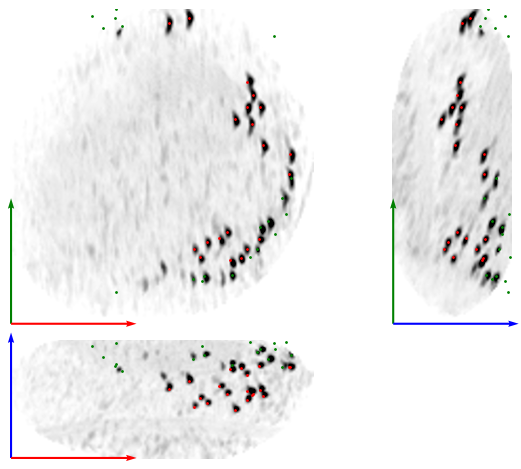

460 460


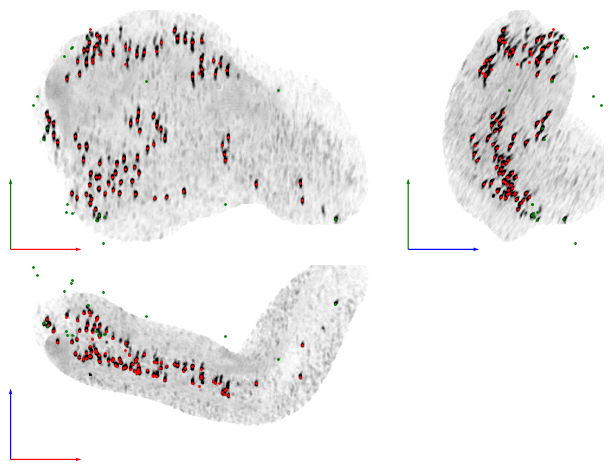

In [ ]:
from findingampa.utils.analysis import find_surfaces
from findingampa.utils.analysis import render_active_zonograms
import pymeshlab
from IPython.display import display
import torch
aunp_dfs = {}
for tomo in tomograms.itertuples():
    name = tomo.name
    label = tomo.Label
    print(name)
    basefolder = Path(f"/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/{label}_tomograms/TOP_TOMOS/{name}/best_alignment")
    aunp_star = basefolder / "aunps" / "aunp_tm_BP.star"

    data = starfile.read(aunp_star)

    amp_rank, amp_pro = calculate_probit(data["faTomo_gaussianFitAmplitude"].to_numpy()* -1)
    pea_rank, pea_pro = calculate_probit(data["faTM_PeakScore"].to_numpy())
   
    Dinv_, Uinv__ = estimate_anisotropic_gaussian_for_probit(amp_pro, pea_pro, None, False, False)
    pval,neg_log_p1q_equ_pro_ = calculate_1q_p_value(amp_pro, pea_pro, Dinv_, Uinv__)
       
    azs = (basefolder / "active_zonograms").glob("active_zonogram_*.mrc")
    for az in azs:
        with mrcfile.open(az, permissive=True) as mrc:
            res_ddw = torch.tensor(mrc.data.copy())

        fig = render_active_zonograms((None,None,res_ddw))
        
        sel_aunps = data[neg_log_p1q_equ_pro_ > 3.8]
      
        az_data = np.load(az.with_suffix(".npy") ,allow_pickle=True)

        presynaptic_glb = basefolder / Path("aunps") / "presynatpticmembranes.glb"
        postsynaptic_glb = basefolder / Path("aunps") / "postsynapticmembranes.glb"
        prems = pymeshlab.MeshSet()
        prems.load_new_mesh(str(presynaptic_glb))
        postms = pymeshlab.MeshSet()
        postms.load_new_mesh(str(postsynaptic_glb))

        prems.set_current_mesh(az_data.tolist()['objects'][0])
        prem = prems.current_mesh()
        pre_points = prem.vertex_matrix().copy()[:,[0,2,1]][::40] * np.array([10,-10,10])
        pre_normals = prem.vertex_normal_matrix().copy()[:,[0,2,1]][::40] * np.array([10,-10,10])
        postms.set_current_mesh(az_data.tolist()['objects'][1])
        postm = postms.current_mesh()
        post_points = postm.vertex_matrix().copy()[:,[0,2,1]][::40] * np.array([10,-10,10])
        post_normals = postm.vertex_normal_matrix().copy()[:,[0,2,1]][::40] * np.array([10,-10,10])
        pre_tree = cKDTree(pre_points)
        post_tree = cKDTree(post_points)


        selected_aunp_pos = sel_aunps[["faTM_PeakX", "faTM_PeakY", "faTM_PeakZ"]].values + sel_aunps[["faTomo_gaussianFitX", "faTomo_gaussianFitY", "faTomo_gaussianFitZ"]].values

        pre_dis, pre_idx = pre_tree.query(selected_aunp_pos)
        post_dis, post_idx = post_tree.query(selected_aunp_pos)
        
        selected_aunp_pos_mask = np.logical_and(pre_dis < 30, post_dis < 30)
        selected_aunp_pos_postsyn_mask = np.logical_and(post_dis < 30, np.logical_not(selected_aunp_pos_mask))
        #selected_aunp_pos_postsyn_mask = np.logical_and(selected_aunp_pos_postsyn_mask,
        # For this to work whe have to select the outer leaflet of the postsynaptic membrane
        #dot_mask = np.einsum('ij,ij->i', post_normals[post_idx], selected_aunp_pos-post_points[post_idx]) > 0
        #print(np.sum(dot_mask),len(dot_mask))
        selected_aunp_pos_masked = selected_aunp_pos[selected_aunp_pos_mask]
        selected_aunp_pos_post = selected_aunp_pos[selected_aunp_pos_postsyn_mask]
        selected_aunp_pos_transformed = (selected_aunp_pos_masked - az_data.tolist()["center"]) @ az_data.tolist()["cs"].T
        selected_aunp_pos_post_transformed = (selected_aunp_pos_post - az_data.tolist()["center"]) @ az_data.tolist()["cs"].T  
        selected_aunp_pos_transformed += np.floor(np.array(res_ddw.shape)[[2,1,0]]/2)
        selected_aunp_pos_post_transformed += np.floor(np.array(res_ddw.shape)[[2,1,0]]/2)
        # Make sure the points are within the volume (remove them if not)
        selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed > 0, axis=1)]
        selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed < np.array(res_ddw.shape)[[2,1,0]], axis=1)]
        selected_aunp_pos_post_transformed = selected_aunp_pos_post_transformed[np.all(selected_aunp_pos_post_transformed > 0, axis=1)]
        selected_aunp_pos_post_transformed = selected_aunp_pos_post_transformed[np.all(selected_aunp_pos_post_transformed < np.array(res_ddw.shape)[[2,1,0]], axis=1)]

        # Get subplot from fig
        (axxy, axxz, axyz) = fig.get_axes()
        axxy.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,1], s=1,c='r')
        axxy.scatter(selected_aunp_pos_post_transformed[:,0], selected_aunp_pos_post_transformed[:,1], s=1,c='g')
        axxz.scatter(selected_aunp_pos_transformed[:,2], selected_aunp_pos_transformed[:,1], s=1,c='r')
        axxz.scatter(selected_aunp_pos_post_transformed[:,2], selected_aunp_pos_post_transformed[:,1], s=1,c='g')
        axyz.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,2], s=1,c='r')
        axyz.scatter(selected_aunp_pos_post_transformed[:,0], selected_aunp_pos_post_transformed[:,2], s=1,c='g')
        display(fig)
        #plt.show()
